In [25]:
# Drop-in additions for the general (p,q) case.
# Assumes you already have: make_grid, u_ab, extreme_points from your script.

import numpy as np
import cvxpy as cp
import math
from typing import Dict, Iterable, List, Tuple, Optional

# ----------------------------
# Utilities
# ----------------------------

def make_grid(d: int, include_endpoints: bool = False) -> np.ndarray:
    """
    Grid on [-1,1].
    - include_endpoints=False: d interior points, avoids division-by-zero in u_{a,b}.
    - include_endpoints=True: includes -1 and 1, can create degeneracies in u_{a,b}.
    """
    if include_endpoints:
        return np.linspace(-1.0, 1.0, d)
    return np.linspace(-1.0, 1.0, d + 2)[1:-1]

def u_ab(x: np.ndarray, a: int, b: int) -> np.ndarray:
    """
    Extreme point u_{a,b} evaluated on grid x.
    a,b are 0-indexed with 0 <= a <= b <= d-1.

    Piecewise definition (in terms of x_i):
      for i <= a:      1 - (x_i+1)/(x_a+1)
      for a < i < b:   0
      for i >= b:      (x_i - x_b)/(1 - x_b)

    Includes safe handling when x_a=-1 or x_b=1 (degenerate chords).
    """
    d = len(x)
    xa, xb = x[a], x[b]
    v = np.zeros(d)

    eps = 1e-12
    for i in range(d):
        if i <= a:
            denom = xa + 1.0
            if abs(denom) < eps:
                # Degenerate: chord from (-1,1) to (-1,0); only defines value 0 at x=-1
                v[i] = 0.0
            else:
                v[i] = 1.0 - (x[i] + 1.0) / denom
        elif i < b:
            v[i] = 0.0
        else:
            denom = 1.0 - xb
            if abs(denom) < eps:
                # Degenerate: chord from (1,0) to (1,1); only defines value 0 at x=1
                v[i] = 0.0
            else:
                v[i] = (x[i] - xb) / denom

    return np.clip(v, 0.0, 1.0)

def extreme_points(d: int, include_endpoints: bool = False):
    x = make_grid(d, include_endpoints=include_endpoints)
    verts = []
    for a in range(d):
        for b in range(a, d):
            verts.append((a, b, u_ab(x, a, b)))
    
    # there is a total of d(d+1)/2 extreme points of the above form
    # there is also the all-one vector if endpoints are included
    if include_endpoints:
        verts.append(( -1, -1, np.ones(d)))  # special case for all-one vector
    return x, verts

def _as_prob_vec(x, d: int, name: str, atol: float = 1e-10) -> np.ndarray:
    x = np.asarray(x, dtype=float).reshape(-1)
    if x.shape[0] != d:
        raise ValueError(f"{name} must have length {d}, got {x.shape[0]}")
    if np.any(x < -atol):
        raise ValueError(f"{name} has negative entries (min={x.min():.3e}).")
    s = float(x.sum())
    if not np.isfinite(s) or abs(s - 1.0) > 1e-8:
        # Small renormalization is ok; big mismatch is likely a bug.
        if s <= 0 or abs(s - 1.0) > 1e-3:
            raise ValueError(f"{name} must sum to 1 (sum={s}).")
        x = np.clip(x, 0.0, np.inf)
        x = x / x.sum()
    else:
        x = np.clip(x, 0.0, np.inf)
        x = x / x.sum()
    return x

def dirichlet_candidates(d: int,
                         n: int,
                         alpha: float = 1.0,
                         min_prob: float = 0.0,
                         seed: Optional[int] = None) -> List[np.ndarray]:
    rng = np.random.default_rng(seed)
    A = np.full(d, float(alpha))
    P = rng.dirichlet(A, size=n)
    if min_prob > 0:
        if min_prob * d >= 1.0:
            raise ValueError("min_prob must satisfy d*min_prob < 1.")
        P = (1.0 - d * min_prob) * P + min_prob
    return [P[i, :] for i in range(n)]

def simplex_lattice(d: int,
                    m: int,
                    min_prob: float = 0.0) -> Iterable[np.ndarray]:
    """
    Exact simplex grid: p_i = k_i / m with integers k_i >= 0, sum k_i = m.
    If min_prob > 0, additionally enforces p_i >= min_prob.

    WARNING: count grows as comb(m+d-1, d-1).
    """
    m = int(m)
    if m <= 0:
        raise ValueError("m must be a positive integer.")

    min_count = int(math.ceil(min_prob * m))
    if d * min_count > m:
        return  # empty generator

    def rec(k: int, remaining: int):
        if k == d - 1:
            if remaining >= min_count:
                yield (remaining,)
            return
        # current count c must leave enough for remaining coords
        lo = min_count
        hi = remaining - min_count * (d - k - 1)
        for c in range(lo, hi + 1):
            for tail in rec(k + 1, remaining - c):
                yield (c,) + tail

    for counts in rec(0, m):
        p = np.array(counts, dtype=float) / float(m)
        yield p

# ----------------------------
# Build a reusable QCQP for fixed q, variable p (as a Parameter)
# ----------------------------

def build_minmax_problem_fixed_q(d: int,
                                 q: np.ndarray,
                                 C: Optional[float] = None,
                                 include_endpoints: bool = False,
                                 impose_q_mean_columns: bool = True):
    """
    Builds the convex QCQP for fixed q and a Parameter p (nonnegative).
    You can then reuse the same compiled problem while sweeping p.

    Problem (for each extreme point v = u_{a,b}):
      theta >= <p - e_k, v> - <q - e_k, (S diag(v) + B) p>     for all k
      t >= C * theta + sum_{j} p_j * sum_i q_i (v_j s_{i,j} + b_{i,j})^2
      minimize t

    Notes on impose_q_mean_columns:
      Since (q - e_k) has sum 0 for every k, the bias is invariant under adding
      a constant multiple of the all-ones vector to \bar{v}. The q-weighted mean
      component only wastes variance. WLOG you can enforce q^T s_j = 0 and q^T b_j = 0.
    """
    if C is None:
        C = float(d)

    q = _as_prob_vec(q, d, "q")
    sqrt_q = np.sqrt(q)

    x, verts = extreme_points(d, include_endpoints=include_endpoints)
    eye = np.eye(d)

    # Decision variables
    S = cp.Variable((d, d))   # columns are s_j
    B = cp.Variable((d, d))   # columns are b_j
    t = cp.Variable()

    # p is a Parameter (so we can sweep it)
    p_param = cp.Parameter(d, nonneg=True)

    constraints = [t >= 0]

    if impose_q_mean_columns:
        constraints += [
            q @ S == np.zeros(d),   # q^T s_j = 0, for each column j
            q @ B == np.zeros(d),   # q^T b_j = 0, for each column j
        ]

    for (_, _, v) in verts:
        # theta_{a,b}
        theta = cp.Variable()

        # bar_v = (S diag(v) + B) p = S (v .* p) + B p
        vp = cp.multiply(v, p_param)     # elementwise: (v_j p_j)
        bar_v = S @ vp + B @ p_param     # in R^d

        # bias constraints: theta >= bias_k for all k
        for k in range(d):
            e_k = eye[k, :]  # numpy row vector length d
            # bias_k = <p-e_k, v> - <q-e_k, bar_v>
            bias_k = cp.sum(cp.multiply(p_param - e_k, v)) - cp.sum(cp.multiply(q - e_k, bar_v))
            constraints += [theta >= bias_k]

        # variance = sum_j p_j * || sqrt(q) .* (v_j s_j + b_j) ||_2^2
        var = 0
        for j in range(d):
            col_j = v[j] * S[:, j] + B[:, j]
            var_j = cp.sum_squares(cp.multiply(sqrt_q, col_j))
            var += p_param[j] * var_j

        constraints += [t >= float(C) * theta + var]

    prob = cp.Problem(cp.Minimize(t), constraints)

    return {
        "prob": prob,
        "p_param": p_param,
        "S": S,
        "B": B,
        "t": t,
        "q": q,
        "C": float(C),
        "x": x,
        "verts": verts,
        "include_endpoints": include_endpoints,
        "impose_q_mean_columns": impose_q_mean_columns,
    }

def solve_for_p(built: Dict,
                p: np.ndarray,
                solver: str = "SCS",
                verbose: bool = False,
                warm_start: bool = True) -> Dict:
    d = built["S"].shape[0]
    p = _as_prob_vec(p, d, "p")
    built["p_param"].value = p

    built["prob"].solve(solver=solver, verbose=verbose, warm_start=warm_start)

    return {
        "status": built["prob"].status,
        "opt_value": built["prob"].value,
        "p": p,
        "q": built["q"].copy(),
        "C": built["C"],
        "S": None if built["S"].value is None else built["S"].value.copy(),
        "B": None if built["B"].value is None else built["B"].value.copy(),
        "x": built["x"],
        "verts": built["verts"],
    }

# ----------------------------
# Evaluation (general p,q)
# ----------------------------

def evaluate_solution_pq(sol: Dict) -> Dict:
    """
    Evaluates max over vertices of: C*bias + variance, with
      bias(v) = max_k [ <p-e_k, v> - <q-e_k, bar_v> ]
      bar_v  = (S diag(v) + B) p
      var(v) = sum_j p_j * sum_i q_i ( (v_j s_{i,j} + b_{i,j})^2 )
    """
    S = sol["S"]
    B = sol["B"]
    p = sol["p"]
    q = sol["q"]
    C = sol["C"]
    verts = sol["verts"]

    if S is None or B is None:
        raise ValueError("Solution has no S/B (solver failed or returned None).")

    d = S.shape[0]

    rows = []
    worst_val = -1e300
    worst = None

    for (a, b, v) in verts:
        E_mat = S @ np.diag(v) + B       # columns: v_j s_j + b_j
        bar_v = E_mat @ p               # \bar{v}

        pv = float(p @ v)
        qbar = float(q @ bar_v)

        # bias components: k-th component = <p-e_k, v> - <q-e_k, bar_v>
        # = (p@v - v_k) - (q@bar_v - bar_v_k) = pv - qbar - v_k + bar_v_k
        bias_components = (pv - qbar) - v + bar_v
        bias = float(np.max(bias_components))

        # variance: sum_j p_j * sum_i q_i E_{i,j}^2
        col_q_norm_sq = np.sum((q[:, None]) * (E_mat ** 2), axis=0)  # length d
        var = float(p @ col_q_norm_sq)

        obj = float(C) * bias + var

        row = {
            "a": a, "b": b,
            "bias": bias,
            "var": var,
            "obj": obj,
            "v": v,
            "vbar": bar_v,
            "bias_components": bias_components,
            "E_mat": E_mat,
        }
        rows.append(row)

        if obj > worst_val:
            worst_val = obj
            worst = row

    return {
        "rows": rows,
        "worst": worst,
        "worst_value": worst_val,
        "worst_a_b_1indexed": (worst["a"] + 1, worst["b"] + 1) if worst is not None else None,
    }

# ----------------------------
# Search over p (grid / random) for fixed q
# ----------------------------

def search_best_p(built: Dict,
                  p_candidates: Iterable[np.ndarray],
                  solver: str = "SCS",
                  verbose: bool = False,
                  warm_start: bool = True,
                  keep_history: bool = True) -> Dict:
    """
    Sweeps p over candidates, solves QCQP for each p, returns best p and its solution.

    Returns dict with:
      - best_sol (full solve output)
      - history: list of {idx, p, status, opt_value} (optional)
    """
    best_sol = None
    best_val = np.inf
    history = []

    for idx, p in enumerate(p_candidates):
        print(f"Evaluating candidate p idx={idx} out of {len(p_candidates)}...")
        sol = solve_for_p(built, p, solver=solver, verbose=verbose, warm_start=warm_start)

        if keep_history:
            history.append({
                "idx": idx,
                "p": sol["p"].copy(),
                "status": sol["status"],
                "opt_value": sol["opt_value"],
                "S": None if sol["S"] is None else sol["S"].copy(),
                "B": None if sol["B"] is None else sol["B"].copy(),
            })

        if sol["status"] in ("optimal", "optimal_inaccurate") and sol["opt_value"] is not None:
            if sol["opt_value"] < best_val:
                best_val = float(sol["opt_value"])
                best_sol = sol
                print(f"New best p at idx={idx}: opt_value={best_val:.6e}")
                print(f"p = {sol['p']}")

    return {
        "best_sol": best_sol,
        "best_value": best_val,
        "history": history if keep_history else None,
    }

d = 7
C = float(d)

# Example: choose a prior q (must be on simplex).
# Here: slightly concentrated toward the middle indices.
idx = np.arange(d)
q_unnorm = np.exp(-0.5 * ((idx - (d - 1) / 2.0) / (0.22 * d)) ** 2)
q = q_unnorm / q_unnorm.sum()
# q = np.ones(d) / d # uniform prior
q = qq

built = build_minmax_problem_fixed_q(
    d=d,
    q=q,
    C=C,
    include_endpoints=True,
    impose_q_mean_columns=True,
)

# Candidate p's:
#  - always include uniform and q itself
#  - plus random Dirichlet samples (practical for d=10)
cand = []
# cand.append(np.ones(d) / d)
cand.append(q.copy())
# cand += dirichlet_candidates(d=d, n=40, alpha=1.0, min_prob=1e-3, seed=0)

# For small d (say d<=5), you can do an exact lattice grid:
cand += list(simplex_lattice(d=d, m=12, min_prob=0.05))

out = search_best_p(
    built=built,
    p_candidates=cand,
    solver="SCS",
    verbose=False,
    warm_start=True,
    keep_history=True,
)

best = out["best_sol"]
print("Best status:", None if best is None else best["status"])
print("Best t*:", out["best_value"])
if best is not None:
    print("Best p:", best["p"])

    stats = evaluate_solution_pq(best)
    print("Worst vertex (a,b) 1-indexed:", stats["worst_a_b_1indexed"])
    print("Worst achieved value:", stats["worst_value"])


Evaluating candidate p idx=0 out of 463...
New best p at idx=0: opt_value=8.649269e-01
p = [0.08333333 0.08333333 0.08333333 0.16666667 0.16666667 0.33333333
 0.08333333]
Evaluating candidate p idx=1 out of 463...
Evaluating candidate p idx=2 out of 463...
Evaluating candidate p idx=3 out of 463...
Evaluating candidate p idx=4 out of 463...
Evaluating candidate p idx=5 out of 463...
Evaluating candidate p idx=6 out of 463...
Evaluating candidate p idx=7 out of 463...
Evaluating candidate p idx=8 out of 463...
Evaluating candidate p idx=9 out of 463...
Evaluating candidate p idx=10 out of 463...
Evaluating candidate p idx=11 out of 463...
Evaluating candidate p idx=12 out of 463...
Evaluating candidate p idx=13 out of 463...
Evaluating candidate p idx=14 out of 463...
Evaluating candidate p idx=15 out of 463...
Evaluating candidate p idx=16 out of 463...
Evaluating candidate p idx=17 out of 463...
Evaluating candidate p idx=18 out of 463...
Evaluating candidate p idx=19 out of 463...
Ev

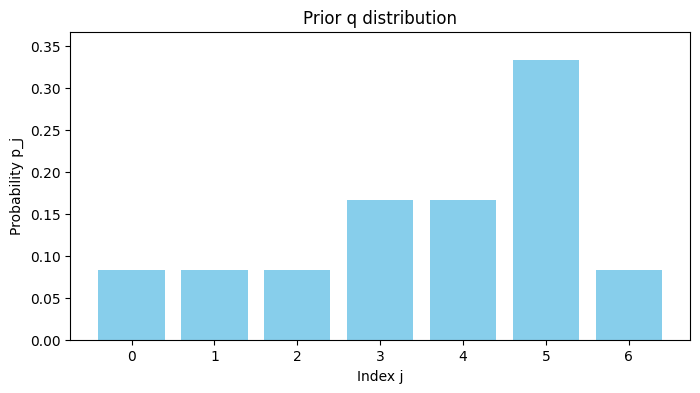

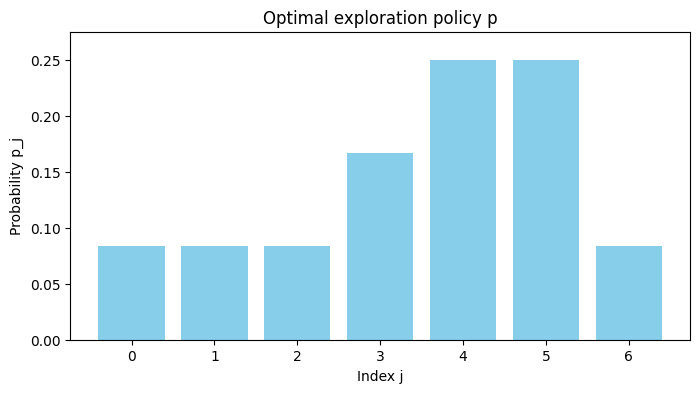

In [27]:
# plot all distributions p in cand
def visualize_distribution_p(p: np.ndarray, d: int, title: str = "", save_prefix: Optional[str] = None, show: bool = True):
    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 4))
    plt.bar(np.arange(d), p, color='skyblue')
    plt.xticks(np.arange(d))
    plt.ylim(0, max(p) * 1.1)
    plt.xlabel('Index j')
    plt.ylabel('Probability p_j')
    plt.title(title)
    if save_prefix is not None:
        plt.savefig(f"{save_prefix}_p_distribution.png")
    if show:
        plt.show()
    plt.close()

# visualize the prior q
visualize_distribution_p(built["q"], d, title="Prior q distribution", save_prefix=None, show=True)
visualize_distribution_p(best["p"], d, title="Optimal exploration policy p", save_prefix=None, show=True)
# for idx, p in enumerate(cand[30:35]):
#     visualize_distribution_p(p, d, title=f"Candidate p idx={idx}", save_prefix=None, show=True)

In [37]:
import numpy as np
import matplotlib.pyplot as plt

def evaluate_solution_pq(sol):
    """
    Compatible with the general (p,q) formulation.

    Expects sol to contain:
      sol["S"], sol["B"], sol["C"], sol["verts"], sol["x"], sol["p"], sol["q"].

    For each vertex v = u_{a,b}:
      E_mat(v)  = S diag(v) + B        (columns: v_j s_j + b_j)
      vbar      = E_mat(v) p
      bias_k    = <p-e_k, v> - <q-e_k, vbar>
      bias      = max_k bias_k
      variance  = sum_j p_j * sum_i q_i * (E_mat(v)_{i,j})^2
      objective = C*bias + variance
    """
    S = sol["S"]
    B = sol["B"]
    C = sol["C"]
    verts = sol["verts"]
    p = sol["p"]
    q = sol["q"]

    d = S.shape[0]
    p = np.asarray(p, dtype=float).reshape(d)
    q = np.asarray(q, dtype=float).reshape(d)

    rows = []
    worst_val = -1e300
    worst = None

    for (a, b, v) in verts:
        v = np.asarray(v, dtype=float).reshape(d)

        # E_mat(v): columns are E(j,v_j) = v_j s_j + b_j
        E_mat = S @ np.diag(v) + B

        # vbar = sum_j p_j E(j,v_j)
        vbar = E_mat @ p

        # bias components:
        # bias_k = <p-e_k, v> - <q-e_k, vbar>
        #        = (p@v - v_k) - (q@vbar - vbar_k)
        pv = float(p @ v)
        qvbar = float(q @ vbar)
        bias_components = (pv - qvbar) - v + vbar
        bias = float(np.max(bias_components))

        # variance: sum_j p_j * sum_i q_i * E_{i,j}^2
        col_q_norm_sq = np.sum(q[:, None] * (E_mat ** 2), axis=0)   # length d, j-th is sum_i q_i E_{i,j}^2
        var = float(p @ col_q_norm_sq)

        val = float(C) * bias + var

        row = {
            "a": a, "b": b,
            "bias": bias,
            "var": var,
            "obj": val,
            "v": v,
            "vbar": vbar,
            "r": v - vbar,  # residual (still useful to plot)
            "bias_components": bias_components,
            "E_mat": E_mat,
            "col_q_norm_sq": col_q_norm_sq,
        }
        rows.append(row)

        if val > worst_val:
            worst_val = val
            worst = row

    return {
        "rows": rows,
        "worst": worst,
        "worst_value": worst_val,
        "worst_a_b_1indexed": (worst["a"] + 1, worst["b"] + 1) if worst is not None else None,
    }

def plot_heatmap(A, title, xlabel="column", ylabel="row"):
    plt.figure()
    plt.imshow(A, aspect="auto")
    plt.colorbar()
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()

def plot_vertices(x, stats):
    plt.figure()
    worst_value = stats["worst_value"]
    for stat in stats["rows"]:
        v = stat["v"]
        alpha = 0.2 if worst_value <= 0 else max(0.05, min(1.0, stat["obj"] / worst_value))
        plt.plot(x, v, marker="o", linewidth=1, alpha=alpha)
    plt.title("Extreme points u_{a,b} on the grid")
    plt.xlabel("x")
    plt.ylabel("u_{a,b}(x)")
    plt.tight_layout()

def plot_bias_variance_scatter(stats):
    rows = stats["rows"]
    biases = np.array([r["bias"] for r in rows])
    vars_ = np.array([r["var"] for r in rows])
    objs = np.array([r["obj"] for r in rows])

    plt.figure()
    plt.scatter(biases, vars_)
    for i, r in enumerate(rows):
        plt.annotate(f"({r['a']+1},{r['b']+1})", (biases[i], vars_[i]), fontsize=8)

    plt.title("Bias vs variance across vertices (under optimal S,B)")
    plt.xlabel("bias = max_k [<p-e_k,v> - <q-e_k,vbar>]")
    plt.ylabel("variance = sum_j p_j * sum_i q_i E_{i,j}^2")
    plt.tight_layout()

    plt.figure()
    plt.hist(objs, bins=max(5, len(objs)//2))
    plt.title("Histogram of objective values across vertices")
    plt.xlabel("C*bias + variance")
    plt.ylabel("count")
    plt.tight_layout()

def plot_worst_case_details(x, worst, C, p=None, q=None):
    v = worst["v"]
    vbar = worst["vbar"]
    r = worst["r"]
    bias_components = worst["bias_components"]
    E_mat = worst["E_mat"]

    a, b = worst["a"], worst["b"]
    d = len(v)

    plt.figure()
    plt.plot(x, v, marker="o", label="v (vertex)")
    plt.plot(x, vbar, marker="o", label="vbar = (S diag(v)+B) p")
    plt.plot(x, r, marker="x", label="r = v - vbar")
    plt.title(f"Worst vertex v vs vbar (a,b)=({a+1},{b+1})")
    plt.xlabel("x")
    plt.ylabel("value")
    plt.legend()
    plt.tight_layout()

    plt.figure()
    plt.bar(np.arange(1, d+1), bias_components)
    plt.title("Bias components: <p-e_k, v> - <q-e_k, vbar>")
    plt.xlabel("k")
    plt.ylabel("value")
    plt.tight_layout()

    # Column norms ||E(:,j)|| (unweighted) and q-weighted column norms (sqrt(q) weighting)
    col_norms = np.linalg.norm(E_mat, axis=0)
    plt.figure()
    plt.bar(np.arange(1, d+1), col_norms)
    plt.title("Unweighted column norms ||E(:,j)|| on worst vertex")
    plt.xlabel("j")
    plt.ylabel("norm")
    plt.tight_layout()

    if q is not None:
        q = np.asarray(q, dtype=float).reshape(d)
        col_q_norm = np.sqrt(np.sum(q[:, None] * (E_mat ** 2), axis=0))
        plt.figure()
        plt.bar(np.arange(1, d+1), col_q_norm)
        plt.title("q-weighted column norms sqrt(sum_i q_i E_{i,j}^2) on worst vertex")
        plt.xlabel("j")
        plt.ylabel("q-weighted norm")
        plt.tight_layout()

    # Objective decomposition
    bias = worst["bias"]
    var = worst["var"]
    plt.figure()
    plt.bar(["C*bias", "variance", "total"], [C*bias, var, C*bias + var])
    plt.title("Objective decomposition on worst vertex")
    plt.tight_layout()

    # Optional: show p and q if provided
    if p is not None:
        p = np.asarray(p, dtype=float).reshape(d)
        plt.figure()
        plt.bar(np.arange(1, d+1), p)
        plt.title("Exploration policy p")
        plt.xlabel("index")
        plt.ylabel("probability")
        plt.tight_layout()

    if q is not None:
        q = np.asarray(q, dtype=float).reshape(d)
        plt.figure()
        plt.bar(np.arange(1, d+1), q)
        plt.title("Prior policy q")
        plt.xlabel("index")
        plt.ylabel("probability")
        plt.tight_layout()

def plot_S_B_columns(S, B):
    d = S.shape[0]
    indices = np.arange(1, d + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    for i in range(d):
        plt.plot(indices, S[:, i], marker='o', label=f's_{i+1}')
    plt.title('Columns of S')
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()

    plt.subplot(1, 2, 2)
    for i in range(d):
        plt.plot(indices, B[:, i], marker='o', label=f'b_{i+1}')
    plt.title('Columns of B')
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()

    plt.tight_layout()
    plt.show()

def visualize_solution(sol, stats, save_prefix=None, show=True, heatmaps=True, worst_case=True):
    S = sol["S"]
    B = sol["B"]
    x = sol["x"]
    C = sol["C"]
    p = sol.get("p", None)
    q = sol.get("q", None)

    worst = stats["worst"]

    # visualize p
    visualize_distribution_p(p, len(p), title="Optimal exploration policy p", save_prefix=None, show=True)
    # visualize q
    visualize_distribution_p(q, len(q), title="Prior q distribution", save_prefix=None, show=True)
    plot_S_B_columns(S, B)

    if heatmaps:
        plot_heatmap(S, "Heatmap of S (columns are s(j))", xlabel="j (column)", ylabel="row i")
        plot_heatmap(B, "Heatmap of B (columns are b(j))", xlabel="j (column)", ylabel="row i")

    plot_bias_variance_scatter(stats)
    if worst_case:
        plot_worst_case_details(x, worst, C, p=p, q=q)

    if save_prefix is not None:
        for i, fig_num in enumerate(plt.get_fignums(), start=1):
            fig = plt.figure(fig_num)
            fig.savefig(f"{save_prefix}_{i:02d}.png", dpi=200, bbox_inches="tight")

    if show:
        plt.show()


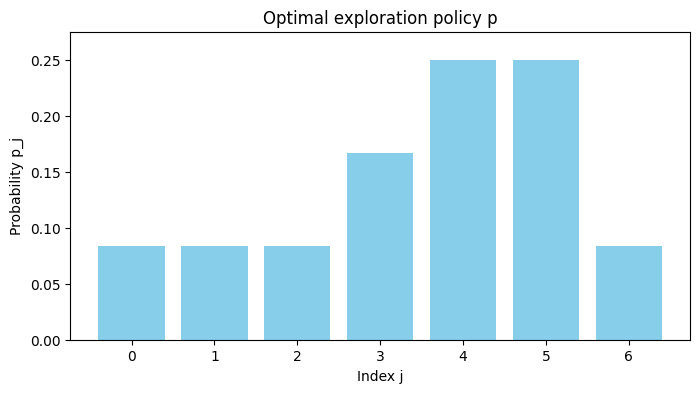

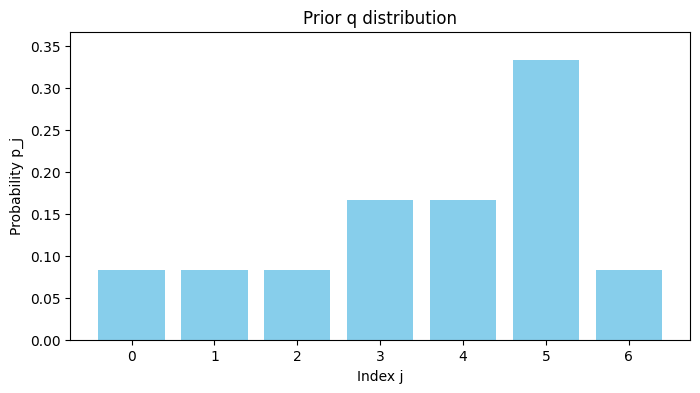

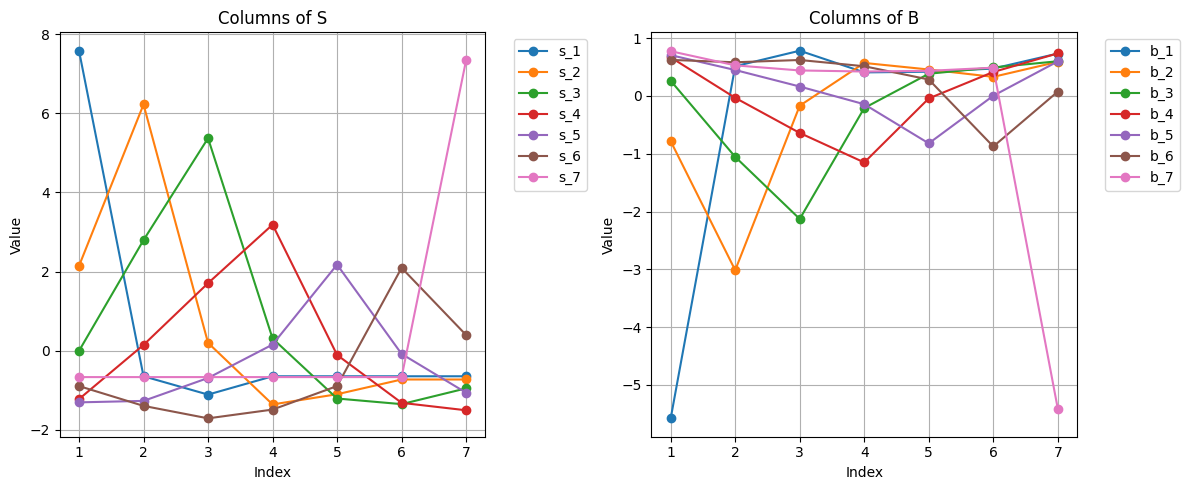

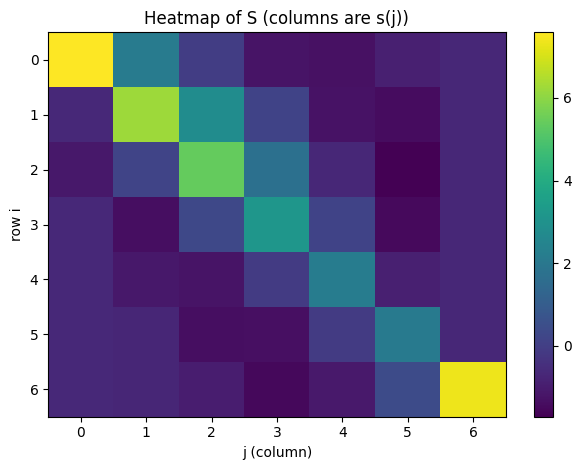

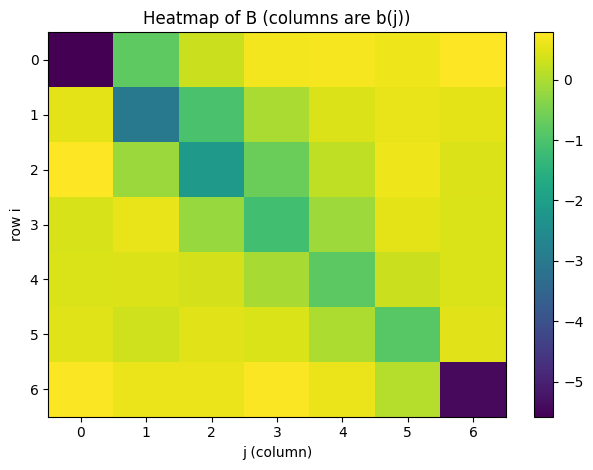

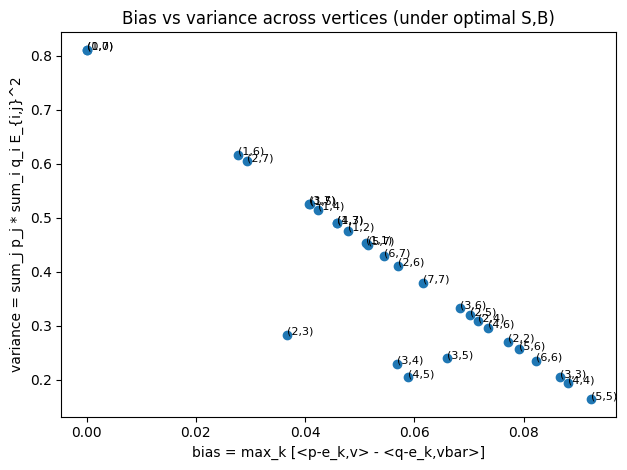

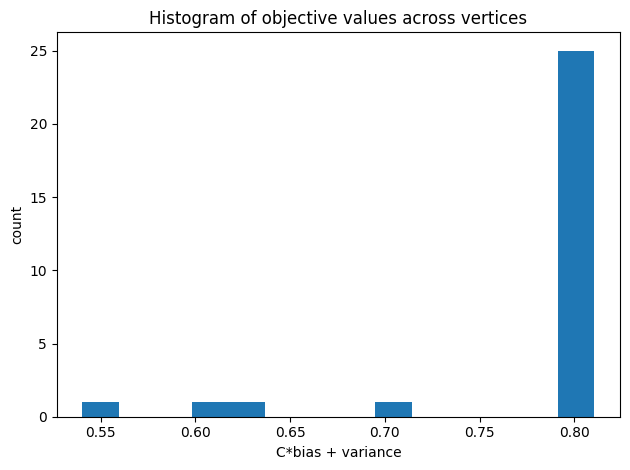

In [38]:
stats = evaluate_solution_pq(best)
visualize_solution(best, stats, save_prefix=None, show=True, heatmaps=True, worst_case=False)

SyntaxError: incomplete input (2364377800.py, line 4)